In [1]:
from pathlib import Path
from dataclasses import dataclass
import json
import math
import random
import urllib.request

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.checkpoint import checkpoint
from pytorch_msssim import ssim

In [2]:
class Surfel(nn.Module):
    
    def __init__(
        self,
        center=(0.0, 0.0, 0.0),
        normal=(0.0, 0.0, 1.0),
        scale=(1.0, 1.0),
        rotation=0.0,
        color=(1.0, 0.0, 0.0),
        opacity=1.0,
    ):
        super().__init__()

        # 3D position
        self.center = nn.Parameter(
            torch.tensor(center, dtype=torch.float32)
        )

        # Raw normal; normalized whenever we use it
        self.normal_raw = nn.Parameter(
            torch.tensor(normal, dtype=torch.float32)
        )

        # Two dimensions because a surfel is a 2D patch in 3D space.
        # Store log(scale) so scale always stays positive.
        self.log_scale = nn.Parameter(
            torch.log(torch.tensor(scale, dtype=torch.float32))
        )

        # Rotation around the surfel normal
        self.rotation = nn.Parameter(
            torch.tensor(rotation, dtype=torch.float32)
        )

        # Raw values converted into [0, 1]
        self.color_raw = nn.Parameter(
            torch.logit(
                torch.tensor(color, dtype=torch.float32).clamp(1e-4, 1 - 1e-4)
            )
        )

        self.opacity_raw = nn.Parameter(
            torch.logit(
                torch.tensor(opacity, dtype=torch.float32).clamp(1e-4, 1 - 1e-4)
            )
        )

    @property
    def normal(self):
        """Unit surface normal."""
        return F.normalize(self.normal_raw, dim=0)

    @property
    def scale(self):
        """Positive x/y scale in the surfel's local plane."""
        return torch.exp(self.log_scale)

    @property
    def color(self):
        """RGB colour restricted to [0, 1]."""
        return torch.sigmoid(self.color_raw)

    @property
    def opacity(self):
        """Opacity restricted to [0, 1]."""
        return torch.sigmoid(self.opacity_raw)

    def local_axes(self):
        """
        Construct two orthogonal tangent vectors u and v
        perpendicular to the surfel normal.
        """
        n = self.normal

        # Pick a reference vector that isn't parallel to n
        if torch.abs(n[2]) < 0.9:
            reference = torch.tensor(
                [0.0, 0.0, 1.0],
                dtype=n.dtype,
                device=n.device
            )
        else:
            reference = torch.tensor(
                [0.0, 1.0, 0.0],
                dtype=n.dtype,
                device=n.device
            )

        # First tangent direction
        u = F.normalize(torch.cross(reference, n, dim=0), dim=0)

        # Second tangent direction
        v = torch.cross(n, u, dim=0)

        # Rotate the tangent axes around the normal
        theta = self.rotation

        rotated_u = torch.cos(theta) * u + torch.sin(theta) * v
        rotated_v = -torch.sin(theta) * u + torch.cos(theta) * v

        return rotated_u, rotated_v

    def points(self, radial_samples=20, angular_samples=80):
        """
        Generate points over an elliptical surfel for visualization.

        Returns:
            Tensor of shape [radial_samples * angular_samples, 3]
        """
        device = self.center.device

        r = torch.linspace(
            0.0,
            1.0,
            radial_samples,
            device=device
        )

        theta = torch.linspace(
            0.0,
            2.0 * torch.pi,
            angular_samples + 1,
            device=device
        )[:-1]

        r_grid, theta_grid = torch.meshgrid(
            r,
            theta,
            indexing="ij"
        )

        # Local coordinates
        x = r_grid * torch.cos(theta_grid) * self.scale[0]
        y = r_grid * torch.sin(theta_grid) * self.scale[1]

        u, v = self.local_axes()

        # Convert local coordinates into world-space coordinates
        points = (
            self.center
            + x[..., None] * u
            + y[..., None] * v
        )

        return points.reshape(-1, 3)

    def plot(self, show_normal=False, ax=None, radial_samples=20, angular_samples=80):

        # Create a 3D axis if one was not supplied
        if ax is None:
            fig = plt.figure(figsize=(8, 8))
            ax = fig.add_subplot(111, projection="3d")

        # Generate surfel points
        pts = self.points(
            radial_samples=radial_samples,
            angular_samples=angular_samples
        )

        # Detach from PyTorch graph before using NumPy / Matplotlib
        pts = pts.detach().cpu().numpy()

        color = self.color.detach().cpu().numpy()
        center = self.center.detach().cpu().numpy()
        normal = self.normal.detach().cpu().numpy()
        scale = self.scale.detach().cpu().numpy()

        # Plot surfel points
        ax.scatter(
            pts[:, 0],
            pts[:, 1],
            pts[:, 2],
            color=color,
            alpha=float(self.opacity.detach().cpu()),
            s=8
        )

        if show_normal:
            ax.quiver(
                center[0],
                center[1],
                center[2],
                normal[0],
                normal[1],
                normal[2],
                length=max(scale) * 1.3,
                normalize=True,
                color="blue",
                linewidth=2,
            )

        # --------------------------------------------------
        # Axis formatting
        # --------------------------------------------------
        ax.set_xlabel("X")
        ax.set_ylabel("Y")
        ax.set_zlabel("Z")

        ax.set_title("Surfel")

        # Keep approximately equal axis proportions
        max_scale = max(scale) * 2

        ax.set_xlim(
            center[0] - max_scale,
            center[0] + max_scale
        )

        ax.set_ylim(
            center[1] - max_scale,
            center[1] + max_scale
        )

        ax.set_zlim(
            center[2] - max_scale,
            center[2] + max_scale
        )

        ax.set_box_aspect((1, 1, 1))

        return ax

    def forward(self):
        return {
            "center": self.center,
            "normal": self.normal,
            "scale": self.scale,
            "rotation": self.rotation,
            "color": self.color,
            "opacity": self.opacity,
        }

<Axes3D: title={'center': 'Surfel'}, xlabel='X', ylabel='Y', zlabel='Z'>

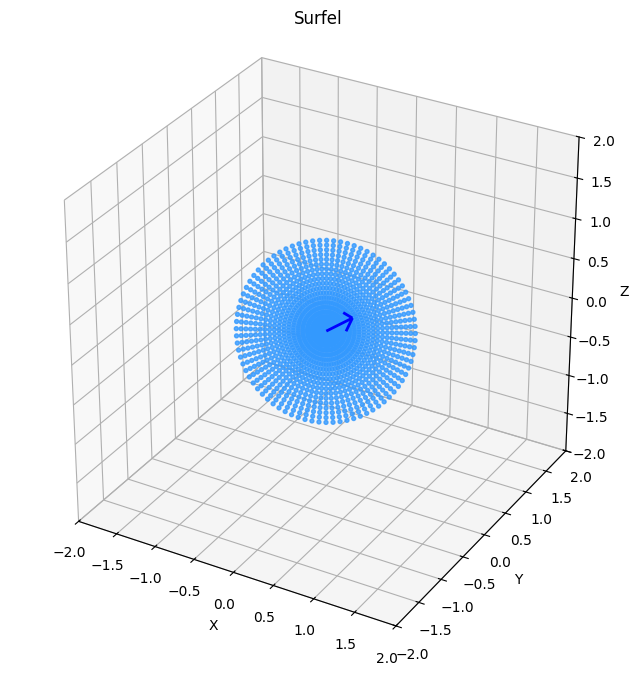

In [3]:
surfel = Surfel(
    center=(0.0, 0.0, 0.0),
    normal=(1.0, -1.0, 1.0),
    scale=(1.0, 1.0),
    rotation=0.0,
    color=(0.2, 0.6, 1.0),
    opacity=0.8
)

surfel.plot(show_normal=True)

In [4]:
"""
Setup Stuff
"""

SEED = 7
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DATA_DIR = Path("data/lego_small")
DATA_DIR.mkdir(parents=True, exist_ok=True)

HF_BASE = (
    "https://huggingface.co/datasets/"
    "rishitdagli/nerf-gs-datasets/resolve/main/lego"
)

IMAGE_SIZE = 128
NUM_SURFELS = 8000
STEPS = 500

if torch.backends.mps.is_available():
    DEVICE = torch.device("mps")
elif torch.cuda.is_available():
    DEVICE = torch.device("cuda")
else:
    DEVICE = torch.device("cpu")

print("Device:", DEVICE)

def download_if_missing(url: str, destination: Path):
    destination.parent.mkdir(parents=True, exist_ok=True)
    if not destination.exists():
        print("Downloading", destination.name)
        urllib.request.urlretrieve(url, destination)
    return destination


transforms_path = download_if_missing(
    f"{HF_BASE}/transforms_train.json",
    DATA_DIR / "transforms_train.json",
)

with open(transforms_path, "r") as f:
    transforms = json.load(f)

frames = transforms["frames"]
print("Training frames in metadata:", len(frames))
VIEW_INDICES = list(range(0, len(frames)))
print("camera_angle_x:", transforms["camera_angle_x"])

selected_frames = [frames[i] for i in VIEW_INDICES]

for frame in selected_frames:
    # Example metadata path: ./train/r_0
    relative = frame["file_path"].removeprefix("./") + ".png"
    destination = DATA_DIR / relative
    download_if_missing(f"{HF_BASE}/{relative}", destination)

def load_rgba_on_white(path: Path, size: int) -> torch.Tensor:
    image = Image.open(path).convert("RGBA")
    image = image.resize((size, size), Image.Resampling.LANCZOS)

    rgba = np.asarray(image, dtype=np.float32) / 255.0
    rgb = rgba[..., :3]
    alpha = rgba[..., 3:4]

    rgb_white = rgb * alpha + (1.0 - alpha)
    return torch.from_numpy(rgb_white), torch.from_numpy(alpha > 0.10)


target_images = []
foreground_masks = []
for frame in selected_frames:
    relative = frame["file_path"].removeprefix("./") + ".png"
    rgb, mask = load_rgba_on_white(DATA_DIR / relative, IMAGE_SIZE)
    target_images.append(rgb)
    foreground_masks.append(mask)
    
"""
fig, axes = plt.subplots(1, len(target_images), figsize=(3 * len(target_images), 3))
axes = np.atleast_1d(axes)
for ax, image, frame_index, frame in zip(axes, target_images, VIEW_INDICES, selected_frames):
    ax.imshow(image.numpy())
    ax.set_title(f"Frame {frame_index}: {Path(frame['file_path']).name}")
    ax.axis("off")
plt.tight_layout()
plt.show()
"""


Device: cuda
Training frames in metadata: 100
camera_angle_x: 0.6911112070083618


'\nfig, axes = plt.subplots(1, len(target_images), figsize=(3 * len(target_images), 3))\naxes = np.atleast_1d(axes)\nfor ax, image, frame_index, frame in zip(axes, target_images, VIEW_INDICES, selected_frames):\n    ax.imshow(image.numpy())\n    ax.set_title(f"Frame {frame_index}: {Path(frame[\'file_path\']).name}")\n    ax.axis("off")\nplt.tight_layout()\nplt.show()\n'

In [5]:
class SurfelScene(nn.Module):
    """One trainable tensor per attribute, rather than 6 Parameters per surfel.

    Individual Surfel objects are used only during initialization/plotting.
    Packing their values here retains the same parameterization for training.
    """
    PARAMETER_NAMES = (
        "centers", "normal_raw", "log_scale", "rotations",
        "color_raw", "opacity_raw",
    )

    def __init__(self, surfels):
        super().__init__()
        if not surfels:
            raise ValueError("A scene must contain at least one surfel.")
        self.centers = nn.Parameter(torch.stack([s.center.detach() for s in surfels]))
        self.normal_raw = nn.Parameter(torch.stack([s.normal_raw.detach() for s in surfels]))
        self.log_scale = nn.Parameter(torch.stack([s.log_scale.detach() for s in surfels]))
        self.rotations = nn.Parameter(torch.stack([s.rotation.detach() for s in surfels]))
        self.color_raw = nn.Parameter(torch.stack([s.color_raw.detach() for s in surfels]))
        self.opacity_raw = nn.Parameter(torch.stack([s.opacity_raw.detach() for s in surfels]))

    def __len__(self):
        return self.centers.shape[0]

    def stacked_parameters(self):
        # No more Python loops or thousands of torch.stack autograd nodes.
        normals = F.normalize(self.normal_raw, dim=1, eps=1e-8)
        scales = self.log_scale.exp()
        colors = self.color_raw.sigmoid()
        opacities = self.opacity_raw.sigmoid()
        return self.centers, normals, scales, self.rotations, colors, opacities

    @torch.no_grad()
    def surfel_snapshot(self, index):
        """Return one independent Surfel for the original plot() helper."""
        if not 0 <= index < len(self):
            raise IndexError(index)
        centers, normals, scales, rotations, colors, opacities = self.stacked_parameters()
        return Surfel(
            center=centers[index].cpu(),
            normal=normals[index].cpu(),
            scale=scales[index].cpu(),
            rotation=rotations[index].cpu(),
            color=colors[index].cpu(),
            opacity=opacities[index].cpu(),
        )


def make_random_scene(num_surfels, seed=7):
    rng = np.random.default_rng(seed)
    surfels = []

    for _ in range(num_surfels):
        # The synthetic LEGO object is approximately around the world origin.
        center = rng.uniform(-1.25, 1.25, size=3)

        # Start normals roughly random, but biased away from the zero vector.
        normal = rng.normal(size=3)
        normal[2] += 0.5

        scale = rng.uniform(0.18, 0.38, size=2)
        rotation = rng.uniform(-math.pi, math.pi)
        color = rng.uniform(0.15, 0.85, size=3)

        surfels.append(
            Surfel(
                center=center,
                normal=normal,
                scale=scale,
                rotation=rotation,
                color=color,
                opacity=0.45,
            )
        )

    return SurfelScene(surfels)


scene = make_random_scene(NUM_SURFELS, seed=SEED).to(DEVICE)
print("Learnable scalar parameters:", sum(p.numel() for p in scene.parameters()))
print("Parameter tensors:", len(list(scene.parameters())))


Learnable scalar parameters: 104000
Parameter tensors: 6


In [6]:
@dataclass
class Camera:
    c2w: torch.Tensor
    w2c: torch.Tensor
    focal: float


def make_cameras(frames, camera_angle_x, image_size):
    focal = 0.5 * image_size / math.tan(0.5 * camera_angle_x)
    cameras = []

    for frame in frames:
        c2w = torch.tensor(frame["transform_matrix"], dtype=torch.float32)
        w2c = torch.linalg.inv(c2w)
        cameras.append(Camera(c2w=c2w, w2c=w2c, focal=focal))

    return cameras


cameras = make_cameras(
    selected_frames,
    transforms["camera_angle_x"],
    IMAGE_SIZE,
)

print("Focal length at resized resolution:", cameras[0].focal)
print("First camera position:", cameras[0].c2w[:3, 3])

Focal length at resized resolution: 177.77776499100293
First camera position: tensor([-0.0538,  3.8455,  1.2081])


In [7]:
def project_points(points, camera, H, W):
    """
    points: [N, 3] world-space points
    returns:
        uv: [N, 2] pixel coordinates
        depth: [N] positive depth in front of the camera
    """
    device = points.device
    w2c = camera.w2c.to(device)

    ones = torch.ones((points.shape[0], 1), device=device, dtype=points.dtype)
    points_h = torch.cat([points, ones], dim=1)
    camera_points = points_h @ w2c.T

    x = camera_points[:, 0]
    y = camera_points[:, 1]
    depth = -camera_points[:, 2]

    safe_depth = depth.clamp_min(1e-4)

    # Perspective projection
    u = camera.focal * x / safe_depth + W / 2.0
    v = -camera.focal * y / safe_depth + H / 2.0

    return torch.stack([u, v], dim=1), depth

In [8]:
SCENE_BOUNDS = (-1.5, 1.5)
HULL_RESOLUTION = 48       # 48^3 candidate locations; increase for finer details
HULL_CAMERA_STRIDE = 2    # use every second view for visual-hull construction

PRUNE_START = 100          # allow surfels to learn before pruning
PRUNE_EVERY = 50
PRUNE_MIN_OPACITY = 0.025
PRUNE_MIN_FOREGROUND_FRACTION = 0.55
PRUNE_CAMERA_STRIDE = 3
PRUNE_MIN_SURFELS = 64


def project_points_numpy(points, camera, image_size):
    """Project [N,3] world points, using the same convention as render_scene."""
    w2c = camera.w2c.detach().cpu().numpy()
    xyz = points @ w2c[:3, :3].T + w2c[:3, 3]
    depth = -xyz[:, 2]
    safe_depth = np.maximum(depth, 1e-4)
    u = camera.focal * xyz[:, 0] / safe_depth + image_size / 2
    v = -camera.focal * xyz[:, 1] / safe_depth + image_size / 2
    return u, v, depth


def expanded_masks(masks, margin=3):
    """Allow a few pixels of silhouette uncertainty at low image resolution."""
    batch = torch.stack(masks).to(dtype=torch.float32)[:, None]
    batch = F.max_pool2d(batch, kernel_size=2 * margin + 1,
                         stride=1, padding=margin)
    return batch[:, 0].numpy().astype(bool)


def foreground_membership(points, cameras, masks_np, camera_stride=1,
                          require_visible=True):
    """Count views where projected centers lie inside image and foreground.

    points: NumPy [N,3] in world coordinates
    masks_np: [V,H,W] boolean masks (optionally expanded)
    returns: visible_count, foreground_count
    """
    size = masks_np.shape[1]
    visible_count = np.zeros(len(points), dtype=np.int32)
    foreground_count = np.zeros(len(points), dtype=np.int32)
    for i in range(0, len(cameras), camera_stride):
        u, v, depth = project_points_numpy(points, cameras[i], size)
        valid = ((depth > 0.05) & (u >= 0) & (u < size)
                 & (v >= 0) & (v < size))
        visible_count += valid
        ix = np.clip(np.rint(u).astype(np.int64), 0, size - 1)
        iy = np.clip(np.rint(v).astype(np.int64), 0, size - 1)
        foreground_count += valid & masks_np[i, iy, ix]
    return visible_count, foreground_count


def make_visual_hull(cameras, masks, bounds=(-1.5, 1.5),
                     resolution=48, camera_stride=2, mask_margin=3):
    """Intersect the silhouette cones from multiple cameras on a 3D grid.

    This is an approximate *visual hull*, not true recovered depth.
    """
    lo, hi = bounds
    axis = np.linspace(lo, hi, resolution, dtype=np.float32)
    points = np.stack(np.meshgrid(axis, axis, axis, indexing="ij"),
                      axis=-1).reshape(-1, 3)
    masks_np = expanded_masks(masks, margin=mask_margin)

    # Restrict to voxels that remain compatible with every inspected view.
    occupied_flat = np.ones(len(points), dtype=bool)
    for i in range(0, len(cameras), camera_stride):
        indices = np.flatnonzero(occupied_flat)
        if len(indices) == 0:
            break
        u, v, depth = project_points_numpy(points[indices], cameras[i],
                                           masks_np.shape[1])
        size = masks_np.shape[1]
        in_frame = ((depth > 0.05) & (u >= 0) & (u < size)
                    & (v >= 0) & (v < size))
        ix = np.clip(np.rint(u).astype(np.int64), 0, size - 1)
        iy = np.clip(np.rint(v).astype(np.int64), 0, size - 1)
        occupied_flat[indices] = in_frame & masks_np[i, iy, ix]

    occupied = occupied_flat.reshape(resolution, resolution, resolution)
    if not occupied.any():
        raise ValueError(
            "Visual hull is empty. Check SCENE_BOUNDS, camera transforms, "
            "alpha masks, and HULL_RESOLUTION; try a larger mask_margin."
        )
    return points, occupied, float(axis[1] - axis[0])


def visual_hull_surface(occupied, voxel_size):
    """Find boundary voxels and approximate their outward surface normals."""
    padded = np.pad(occupied, 1, mode="constant", constant_values=False)
    x, y, z = occupied.shape
    neighbors = [padded[2:x+2, 1:y+1, 1:z+1],
                 padded[0:x, 1:y+1, 1:z+1],
                 padded[1:x+1, 2:y+2, 1:z+1],
                 padded[1:x+1, 0:y, 1:z+1],
                 padded[1:x+1, 1:y+1, 2:z+2],
                 padded[1:x+1, 1:y+1, 0:z]]
    boundary = occupied & ~np.logical_and.reduce(neighbors)

    # Gradient of a smoothed occupancy field reduces voxel staircase normals.
    # F.avg_pool3d is used only once at initialization, on the CPU.
    occ_t = torch.from_numpy(occupied.astype(np.float32))[None, None]
    smooth = F.avg_pool3d(F.pad(occ_t, (1, 1, 1, 1, 1, 1)),
                          kernel_size=3, stride=1)[0, 0].numpy()
    gradient = np.gradient(smooth, voxel_size)
    outward = -np.stack(gradient, axis=-1)
    return boundary, outward


def initial_surface_colors(centers, normals, cameras, images, masks):
    """Initialize each surfel color from its most front-facing visible view."""
    size = images[0].shape[0]
    colors = np.full((len(centers), 3), 0.6, dtype=np.float32)
    best_score = np.full(len(centers), -np.inf, dtype=np.float32)
    image_np = [img.numpy() for img in images]
    mask_np = [mask.numpy() for mask in masks]

    for camera, image, mask in zip(cameras, image_np, mask_np):
        u, v, depth = project_points_numpy(centers, camera, size)
        valid = ((depth > 0.05) & (u >= 0) & (u < size)
                 & (v >= 0) & (v < size))
        ix = np.clip(np.rint(u).astype(np.int64), 0, size - 1)
        iy = np.clip(np.rint(v).astype(np.int64), 0, size - 1)
        valid &= mask[iy, ix]
        camera_pos = camera.c2w[:3, 3].detach().cpu().numpy()
        to_camera = camera_pos[None, :] - centers
        to_camera /= np.maximum(np.linalg.norm(to_camera, axis=1, keepdims=True), 1e-8)
        facing = np.sum(normals * to_camera, axis=1)
        # Prefer front-facing views but use a rear-facing observation as fallback.
        better = valid & (facing > best_score)
        colors[better] = image[iy[better], ix[better]]
        best_score[better] = facing[better]
    return np.clip(colors, 0.01, 0.99)


def make_initialized_scene(num_surfels, cameras, target_images,
                           foreground_masks, bounds=(-1.5, 1.5),
                           resolution=48, camera_stride=2, seed=7):
    rng = np.random.default_rng(seed)
    points, occupied, voxel = make_visual_hull(
        cameras, foreground_masks, bounds, resolution,
        camera_stride=camera_stride
    )
    boundary, normals_grid = visual_hull_surface(occupied, voxel)
    surface_centers = points[boundary.reshape(-1)]
    surface_normals = normals_grid[boundary]
    if len(surface_centers) == 0:
        raise ValueError("No surface voxels found; increase grid resolution.")

    chosen = rng.choice(len(surface_centers), size=num_surfels,
                        replace=num_surfels > len(surface_centers))
    centers = surface_centers[chosen].copy()
    centers += rng.uniform(-0.20 * voxel, 0.20 * voxel,
                           size=centers.shape).astype(np.float32)
    centers = np.clip(centers, bounds[0], bounds[1])

    normals = surface_normals[chosen].copy()
    norm = np.linalg.norm(normals, axis=1, keepdims=True)
    fallback = centers - np.mean(surface_centers, axis=0, keepdims=True)
    fallback /= np.maximum(np.linalg.norm(fallback, axis=1, keepdims=True), 1e-8)
    normals = np.where(norm > 1e-5, normals / np.maximum(norm, 1e-8), fallback)
    normals = normals.astype(np.float32)

    colors = initial_surface_colors(centers, normals, cameras,
                                   target_images, foreground_masks)
    # More surfels means each one should cover a smaller patch.
    scale = float(np.clip(0.85 * voxel * np.sqrt(len(surface_centers) / num_surfels),
                          0.035, 0.25))
    surfels = [Surfel(center=center, normal=normal,
                      scale=(scale, scale), rotation=float(rng.uniform(-math.pi, math.pi)),
                      color=color, opacity=0.55)
               for center, normal, color in zip(centers, normals, colors)]
    print(f"Visual hull: {occupied.sum():,} occupied voxels; "
          f"{len(surface_centers):,} surface voxels; scale={scale:.3f}")
    return SurfelScene(surfels)


foreground_masks = [mask.squeeze(-1) for mask in foreground_masks]

scene = make_initialized_scene(
    NUM_SURFELS, cameras, target_images, foreground_masks,
    bounds=SCENE_BOUNDS, resolution=HULL_RESOLUTION,
    camera_stride=HULL_CAMERA_STRIDE, seed=SEED,
).to(DEVICE)
print("Initial surfels:", len(scene))
print("Learnable scalar parameters:", sum(p.numel() for p in scene.parameters()))


Visual hull: 9,755 occupied voxels; 2,682 surface voxels; scale=0.035
Initial surfels: 8000
Learnable scalar parameters: 104000


In [9]:
def batched_local_axes(normals, rotations):
    """Vectorized version of Surfel.local_axes()."""
    device = normals.device

    ref_z = torch.tensor([0.0, 0.0, 1.0], device=device).expand_as(normals)
    ref_y = torch.tensor([0.0, 1.0, 0.0], device=device).expand_as(normals)
    use_z = (normals[:, 2].abs() < 0.9).unsqueeze(1)
    reference = torch.where(use_z, ref_z, ref_y)

    u = F.normalize(torch.cross(reference, normals, dim=1), dim=1, eps=1e-8)
    v = torch.cross(normals, u, dim=1)

    c = torch.cos(rotations).unsqueeze(1)
    s = torch.sin(rotations).unsqueeze(1)

    rotated_u = c * u + s * v
    rotated_v = -s * u + c * v
    return rotated_u, rotated_v

"""
def render_scene(scene, camera, H=64, W=64, blur=0.25):
    device = next(scene.parameters()).device

    centers, normals, scales, rotations, colors, opacities = scene.stacked_parameters()
    u_axis, v_axis = batched_local_axes(normals, rotations)

    center_2d, depth = project_points(centers, camera, H, W)
    u_2d, _ = project_points(centers + scales[:, 0:1] * u_axis, camera, H, W)
    v_2d, _ = project_points(centers + scales[:, 1:2] * v_axis, camera, H, W)

    axis_u = u_2d - center_2d     # [N, 2]
    axis_v = v_2d - center_2d     # [N, 2]

    # A has projected ellipse axes as its columns.
    A = torch.stack([axis_u, axis_v], dim=2)  # [N, 2, 2]
    covariance = A @ A.transpose(1, 2)
    covariance = covariance + blur * torch.eye(2, device=device).unsqueeze(0)

    # Analytical inverse for symmetric 2x2 covariance matrices.
    a = covariance[:, 0, 0]
    b = covariance[:, 0, 1]
    c = covariance[:, 1, 1]
    det = (a * c - b * b).clamp_min(1e-8)

    inv_cov = torch.stack(
        [c / det, -b / det, -b / det, a / det], dim=1
    ).reshape(-1, 2, 2)

    ys, xs = torch.meshgrid(
        torch.arange(H, device=device, dtype=torch.float32),
        torch.arange(W, device=device, dtype=torch.float32),
        indexing="ij",
    )
    pixels = torch.stack([xs, ys], dim=-1)  # [H, W, 2]

    difference = pixels.unsqueeze(0) - center_2d[:, None, None, :]  # [N,H,W,2]
    mahalanobis = torch.einsum(
        "nhwi,nij,nhwj->nhw", difference, inv_cov, difference
    )
    gaussian = torch.exp(-0.5 * mahalanobis)

    # Smoothly suppress surfels behind the camera.
    visibility = torch.sigmoid(12.0 * (depth - 0.05))
    weights = opacities[:, None, None] * gaussian * visibility[:, None, None]

    weight_sum = weights.sum(dim=0)  # [H,W]
    rgb_sum = (weights[..., None] * colors[:, None, None, :]).sum(dim=0)
    rgb = rgb_sum / (weight_sum[..., None] + 1e-6)

    # Soft coverage and white background.
    coverage = 1.0 - torch.exp(-weight_sum)
    image = coverage[..., None] * rgb + (1.0 - coverage[..., None])
    # Keep a valid gradient graph even if no surfels intersect this view.
    return image.clamp(0.0, 1.0) + 0.0 * centers.sum()
"""


def render_scene(scene, camera, H=64, W=64, blur=1.0,
                 cull_offscreen=True, chunk_size=128):

    device = next(scene.parameters()).device

    centers, normals, scales, rotations, colors, opacities = (
        scene.stacked_parameters()
    )

    u_axis, v_axis = batched_local_axes(normals, rotations)

    # Project surfel centers and axes.
    center_2d, depth = project_points(centers, camera, H, W)

    u_2d, _ = project_points(
        centers + scales[:, 0:1] * u_axis, camera, H, W
    )
    v_2d, _ = project_points(
        centers + scales[:, 1:2] * v_axis, camera, H, W
    )

    axis_u = u_2d - center_2d
    axis_v = v_2d - center_2d

    # Remove surfels that cannot contribute to this image.
    if cull_offscreen:
        pixel_radius = 3.0 * torch.sqrt(
            (axis_u.square() + axis_v.square()).sum(dim=1)
        ) + 3.0

        visible = (
            (depth > 0.05)
            & (center_2d[:, 0] + pixel_radius >= 0)
            & (center_2d[:, 0] - pixel_radius < W)
            & (center_2d[:, 1] + pixel_radius >= 0)
            & (center_2d[:, 1] - pixel_radius < H)
        )

        center_2d = center_2d[visible]
        depth = depth[visible]
        axis_u = axis_u[visible]
        axis_v = axis_v[visible]
        colors = colors[visible]
        opacities = opacities[visible]

    # A shape check avoids a CUDA tensor-to-bool synchronization.
    if center_2d.shape[0] == 0:
        return torch.ones((H, W, 3), device=device) + 0.0 * centers.sum()

    # Sort front-to-back: smaller positive depth is closer.
    order = torch.argsort(depth)

    ys, xs = torch.meshgrid(
        torch.arange(H, device=device, dtype=centers.dtype),
        torch.arange(W, device=device, dtype=centers.dtype),
        indexing="ij",
    )
    pixels = torch.stack([xs, ys], dim=-1)

    rgb = torch.zeros((H, W, 3), device=device)
    transmittance = torch.ones((H, W), device=device)

    eye = torch.eye(2, device=device)

    def render_chunk(idx, rgb, transmittance):

        # Projected Gaussian covariance.
        A = torch.stack(
            [axis_u[idx], axis_v[idx]], dim=-1
        )

        covariance = (
            A @ A.transpose(1, 2) + blur * eye
        )

        a = covariance[:, 0, 0][:, None, None]
        b = covariance[:, 0, 1][:, None, None]
        c = covariance[:, 1, 1][:, None, None]

        det = (a * c - b * b).clamp_min(1e-8)

        diff = pixels[None] - center_2d[idx, None, None, :]
        dx, dy = diff[..., 0], diff[..., 1]

        mahalanobis = (
            c * dx.square()
            - 2 * b * dx * dy
            + a * dy.square()
        ) / det

        gaussian = torch.exp(-0.5 * mahalanobis)

        # Per-pixel opacity.
        visibility = torch.sigmoid(
            12.0 * (depth[idx] - 0.05)
        )

        alpha = (
            opacities[idx, None, None]
            * gaussian
            * visibility[:, None, None]
        ).clamp(0.0, 0.999)

        # Front-to-back alpha compositing.
        remaining = torch.cumprod(1.0 - alpha, dim=0)

        before = torch.cat([
            torch.ones_like(remaining[:1]),
            remaining[:-1],
        ], dim=0)

        contribution = before * alpha

        # Colour contributed by this chunk.
        block_rgb = (
            contribution[..., None]
            * colors[idx, None, None, :]
        ).sum(dim=0)

        rgb = rgb + transmittance[..., None] * block_rgb

        # Transparency remaining after the chunk.
        transmittance = transmittance * remaining[-1]

        return rgb, transmittance

    for idx in order.split(chunk_size):
        if torch.is_grad_enabled():
            rgb, transmittance = checkpoint(
                render_chunk,
                idx, rgb, transmittance,
                use_reentrant=False,
                preserve_rng_state=False
            )
        else:
            rgb, transmittance = render_chunk(
                idx, rgb, transmittance
            )

    # White background.
    image = rgb + transmittance[..., None]

    # Keep a valid gradient graph even if no surfels intersect this view.
    return image.clamp(0.0, 1.0) + 0.0 * centers.sum()


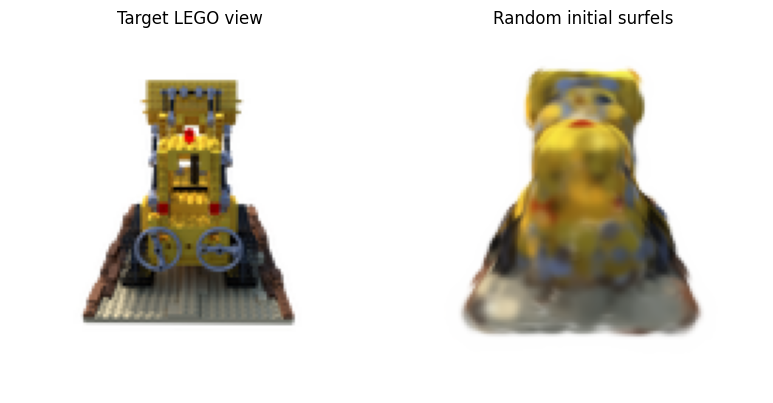

In [10]:
with torch.no_grad():
    initial_render = render_scene(scene, cameras[0], IMAGE_SIZE, IMAGE_SIZE, blur=0.25).cpu()

fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(target_images[0].numpy())
axes[0].set_title("Target LEGO view")
axes[0].axis("off")

axes[1].imshow(initial_render.numpy())
axes[1].set_title("Random initial surfels")
axes[1].axis("off")
plt.tight_layout()
plt.show()


In [11]:
def make_optimizer(scene):
    """Only six parameter tensors; fused CUDA AdamW when available."""
    return torch.optim.AdamW(
        [
            {"params": [scene.centers], "lr": 1.0e-2},
            {"params": [scene.normal_raw], "lr": 2.0e-3},
            {"params": [scene.log_scale], "lr": 3.0e-3},
            {"params": [scene.rotations], "lr": 2.0e-3},
            {"params": [scene.color_raw], "lr": 1.5e-2},
            {"params": [scene.opacity_raw], "lr": 8.0e-3},
        ],
        weight_decay=1e-6,
        fused=(scene.centers.device.type == "cuda"),
    )


@torch.no_grad()
def prune_scene(scene, optimizer, cameras, foreground_masks,
                bounds=(-1.5, 1.5), min_opacity=0.025,
                min_foreground_fraction=0.55, camera_stride=3,
                min_surfels=64, mask_margin=4):
    """Prune rows of each parameter tensor and preserve surviving AdamW moments."""
    before = len(scene)
    centers = scene.centers.detach().cpu().numpy()
    opacities = scene.opacity_raw.detach().sigmoid().cpu().numpy()

    inside = np.all((centers >= bounds[0]) & (centers <= bounds[1]), axis=1)
    masks_np = expanded_masks(foreground_masks, margin=mask_margin)
    visible, foreground = foreground_membership(
        centers, cameras, masks_np, camera_stride=camera_stride
    )
    min_views = min(3, len(range(0, len(cameras), camera_stride)))
    fraction = foreground / np.maximum(visible, 1)
    keep = (inside & (opacities >= min_opacity)
            & (visible >= min_views)
            & (fraction >= min_foreground_fraction))

    kept_count = int(keep.sum())
    if kept_count < min(min_surfels, before):
        print(f"Pruning skipped: only {kept_count}/{before} would survive. "
              "Inspect bounds, foreground masks, or thresholds.")
        return optimizer, 0
    if kept_count == before:
        return optimizer, 0

    keep_t = torch.as_tensor(keep, dtype=torch.bool, device=scene.centers.device)
    old_params = {name: getattr(scene, name) for name in scene.PARAMETER_NAMES}

    # Replacing full batched nn.Parameters requires rebuilding the optimizer.
    for name, old_param in old_params.items():
        setattr(scene, name, nn.Parameter(old_param.detach()[keep_t].clone()))

    new_optimizer = make_optimizer(scene)
    for name, old_param in old_params.items():
        old_state = optimizer.state.get(old_param)
        if old_state is None:
            continue
        new_param = getattr(scene, name)
        new_state = {}
        for state_key, state_value in old_state.items():
            if isinstance(state_value, torch.Tensor):
                # AdamW's exp_avg and exp_avg_sq match the parameter shape.
                if state_value.shape == old_param.shape:
                    new_state[state_key] = state_value[keep_t].clone()
                else:
                    # The scalar step count is unchanged by pruning.
                    new_state[state_key] = state_value.clone()
            else:
                new_state[state_key] = state_value
        new_optimizer.state[new_param] = new_state

    return new_optimizer, before - kept_count


optimizer = make_optimizer(scene)
print("Optimizer parameter tensors:", len(list(scene.parameters())))


Optimizer parameter tensors: 6


In [19]:
targets_device = [image.to(DEVICE) for image in target_images]
loss_history = []
surfel_count_history = []

for step in range(STEPS):
    view_index = random.randrange(len(cameras))
    camera = cameras[view_index]
    target = targets_device[view_index].permute(2, 0, 1).unsqueeze(0)  # [1,3,H,W]

    rendered = render_scene(
        scene, camera, IMAGE_SIZE, IMAGE_SIZE, blur=0.25,
        chunk_size=32,
    ).permute(2, 0, 1).unsqueeze(0)
    loss = 0.8 * F.l1_loss(rendered, target) + 0.2 * (1 - ssim(rendered, target))

    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    optimizer.step()

    # Clamp entire batched tensors with just three operations.
    with torch.no_grad():
        scene.centers.clamp_(-2.0, 2.0)
        scene.log_scale.clamp_(math.log(0.03), math.log(0.8))
        scene.normal_raw.clamp_(-5.0, 5.0)

    # Keep detached values on device; avoid a GPU->CPU sync on every step.
    loss_history.append(loss.detach())

    if step + 1 >= PRUNE_START and (step + 1 - PRUNE_START) % PRUNE_EVERY == 0:
        optimizer, removed = prune_scene(
            scene, optimizer, cameras, foreground_masks,
            bounds=SCENE_BOUNDS, min_opacity=PRUNE_MIN_OPACITY,
            min_foreground_fraction=PRUNE_MIN_FOREGROUND_FRACTION,
            camera_stride=PRUNE_CAMERA_STRIDE,
            min_surfels=PRUNE_MIN_SURFELS,
        )
        print(f"  pruning at step {step+1}: removed {removed}, "
              f"remaining {len(scene)}")

    surfel_count_history.append(len(scene))
    if step % 50 == 0 or step == STEPS - 1:
        print(f"step {step:4d} | view {view_index:2d} | "
              f"surfels {len(scene):4d} | loss {loss.item():.6f}")


step    0 | view 40 | surfels 7990 | loss 0.023829
step   50 | view 81 | surfels 7990 | loss 0.021765
  pruning at step 100: removed 3, remaining 7987
step  100 | view 60 | surfels 7987 | loss 0.024603
  pruning at step 150: removed 1, remaining 7986
step  150 | view  0 | surfels 7986 | loss 0.018766
  pruning at step 200: removed 5, remaining 7981
step  200 | view 63 | surfels 7981 | loss 0.021510
  pruning at step 250: removed 2, remaining 7979
step  250 | view 95 | surfels 7979 | loss 0.030543
  pruning at step 300: removed 3, remaining 7976
step  300 | view 86 | surfels 7976 | loss 0.026332
  pruning at step 350: removed 3, remaining 7973
step  350 | view  3 | surfels 7973 | loss 0.024968
  pruning at step 400: removed 2, remaining 7971
step  400 | view 40 | surfels 7971 | loss 0.022733
  pruning at step 450: removed 2, remaining 7969
step  450 | view  9 | surfels 7969 | loss 0.025647
  pruning at step 500: removed 4, remaining 7965
step  499 | view 11 | surfels 7965 | loss 0.02598

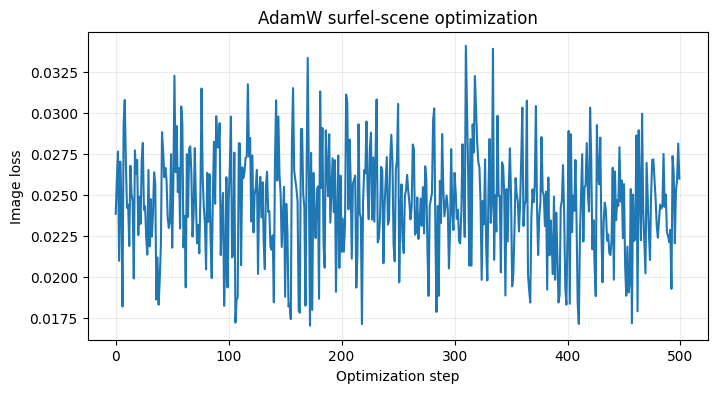

In [20]:
plt.figure(figsize=(8, 4))
plt.plot(torch.stack(loss_history).detach().cpu().numpy())
plt.xlabel("Optimization step")
plt.ylabel("Image loss")
plt.title("AdamW surfel-scene optimization")
plt.grid(alpha=0.25)
plt.show()


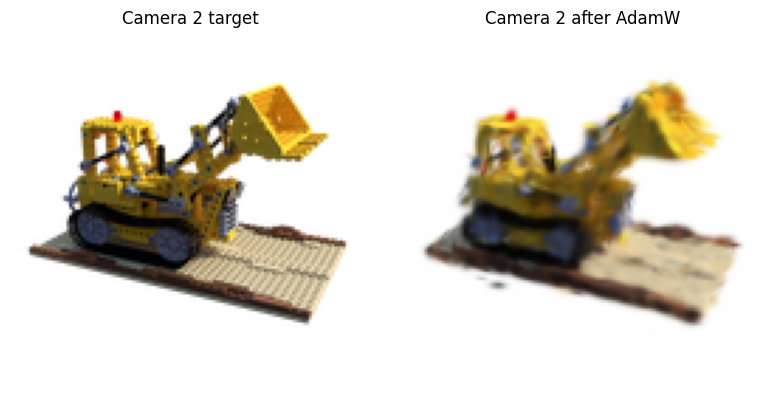

In [23]:
VIEW_INDEX = 2
if not 0 <= VIEW_INDEX < len(cameras):
    raise ValueError(f"VIEW_INDEX must be between 0 and {len(cameras) - 1}.")

with torch.no_grad():
    final_render = render_scene(
        scene, cameras[VIEW_INDEX], IMAGE_SIZE, IMAGE_SIZE, blur=0.25
    ).cpu()

target = target_images[VIEW_INDEX].cpu()
fig, axes = plt.subplots(1, 2, figsize=(8, 4))

axes[0].imshow(target.numpy())
axes[0].set_title(f"Camera {VIEW_INDEX} target")
axes[0].axis("off")

axes[1].imshow(final_render.numpy())
axes[1].set_title(f"Camera {VIEW_INDEX} after AdamW")
axes[1].axis("off")

plt.tight_layout()
plt.show()


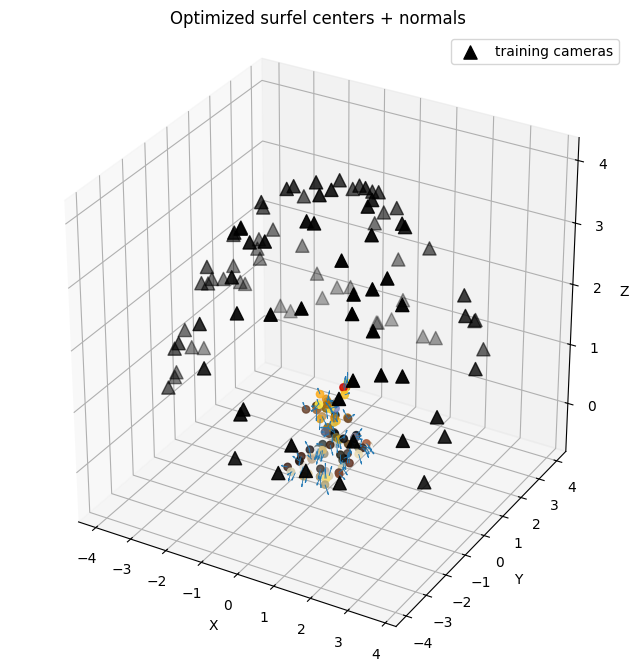

In [15]:
def plot_scene_centers_and_normals(scene, max_surfels=96):
    fig = plt.figure(figsize=(8, 8))
    ax = fig.add_subplot(111, projection="3d")

    centers, normals, _, _, colors, _ = scene.stacked_parameters()
    centers = centers[:max_surfels].detach().cpu().numpy()
    normals = normals[:max_surfels].detach().cpu().numpy()# Process sorted surfels in small batches.
    colors = colors[:max_surfels].detach().cpu().numpy()

    ax.scatter(
        centers[:, 0], centers[:, 1], centers[:, 2],
        c=colors, s=28, alpha=0.85
    )
    ax.quiver(
        centers[:, 0], centers[:, 1], centers[:, 2],
        normals[:, 0], normals[:, 1], normals[:, 2],
        length=0.18, normalize=True, linewidth=0.6
    )

    # Camera centers
    camera_centers = torch.stack([cam.c2w[:3, 3] for cam in cameras]).cpu().numpy()
    ax.scatter(
        camera_centers[:, 0], camera_centers[:, 1], camera_centers[:, 2],
        marker="^", s=90, color="black", label="training cameras"
    )

    ax.set_xlabel("X")
    ax.set_ylabel("Y")
    ax.set_zlabel("Z")
    ax.set_title("Optimized surfel centers + normals")
    ax.set_box_aspect((1, 1, 1))
    ax.legend()
    plt.show()


plot_scene_centers_and_normals(scene)


/tmp/ipykernel_235436/2594988999.py:16: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(center, dtype=torch.float32)
/tmp/ipykernel_235436/2594988999.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.tensor(normal, dtype=torch.float32)
/tmp/ipykernel_235436/2594988999.py:27: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or sourceTensor.detach().clone().requires_grad_(True), rather than torch.tensor(sourceTensor).
  torch.log(torch.tensor(scale, dtype=torch.float32))
/tmp/ipykernel_235436/2594988999.py:32: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.detach().clone() or source

<Axes3D: title={'center': 'Surfel'}, xlabel='X', ylabel='Y', zlabel='Z'>

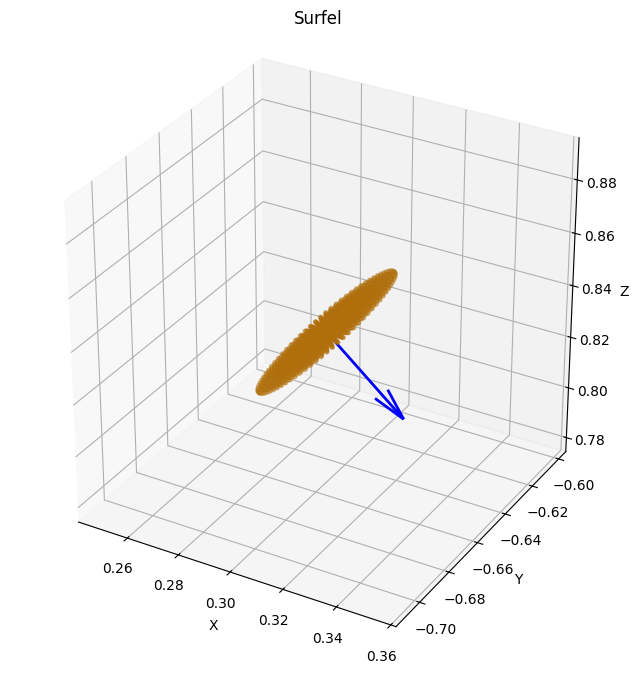

In [16]:
# Snapshot a surviving surfel (the original fixed index may have been pruned).
scene.surfel_snapshot(min(20, len(scene) - 1)).plot(show_normal=True)
